# Telco Customer Churn — Predicting Which Customers Will Leave

**Goal:** predict which telecom customers are likely to churn and choose a decision threshold from an (illustrative) business cost, so that retention offers go to the right customers.

**Data:** IBM's *Telco Customer Churn* sample dataset (7,043 customers, 20 features, ~26.5% churn), saved as `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`. See the README for how to get it.

**Method:** cleaning and EDA → stratified 80/20 split → scikit-learn pipelines (scaling + one-hot encoding) → 5-fold stratified CV to compare Logistic Regression, Decision Tree, Random Forest and Gradient Boosting → cost-based threshold from out-of-fold predictions → one final evaluation on the held-out test set.

## 01. Imports

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split , StratifiedKFold , cross_validate , GridSearchCV , cross_val_predict
from sklearn.preprocessing import StandardScaler , OneHotEncoder 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report , confusion_matrix , roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier


## 02. Data Loading and Inspection

In [4]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head() )
print("___________________________________________________________________________________")
print (df.describe())
print("___________________________________________________________________________________")
print(df.info())
print("__________________________________________________________________________________")
print(df.nunique())
print("__________________________________________________________________________________")
print(df.shape)


FileNotFoundError: [Errno 2] No such file or directory: '../data/WA_Fn-UseC_-Telco-Customer-Churn.csv'

## 03. Data Cleaning

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

NameError: name 'df' is not defined

In [6]:
df.isna().sum()

NameError: name 'df' is not defined

In [7]:
print(df[df['TotalCharges'].isna()][['tenure' , 'TotalCharges' , 'Churn']])

NameError: name 'df' is not defined

We found that the tenure of each of these customers is 0, indicating that they are new customers. Therefore, since they have not yet accumulated any charges, we set their TotalCharges to 0.

In [6]:
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

We check whether any customer ID appears more than once (none does).

In [7]:
print(df['customerID'].duplicated().sum())

0


We drop `customerID`: it is only an identifier and carries no information about whether a customer will churn.

In [8]:
df = df.drop('customerID', axis=1)
print(df.duplicated().sum())

22


After dropping the ID, 22 rows are identical to an earlier row in every feature. They belong to different customers (their IDs differ) and identical profiles are plausible with mostly categorical features, so we keep them. (Identical rows can land on both sides of the split; with so few of them the effect is negligible.)

Checking for suspicious numerical data

In [9]:
df.select_dtypes(include="number").describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [10]:
num_cols = df.select_dtypes(include='number').drop(columns='SeniorCitizen')

Q1 = num_cols.quantile(0.25)
Q3 = num_cols.quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    ((num_cols < Q1 - 1.5 * IQR) |
     (num_cols > Q3 + 1.5 * IQR)).any(axis=1)
]
print(outliers.select_dtypes(include='number'))

Empty DataFrame
Columns: [SeniorCitizen, tenure, MonthlyCharges, TotalCharges]
Index: []


Good: there are no negative values and no IQR outliers.

Note: we left out the numeric column `SeniorCitizen` because it is a binary variable, so looking for IQR outliers in it makes no sense.

In [11]:
df['Churn'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [12]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

## 04. Exploratory Data Analysis

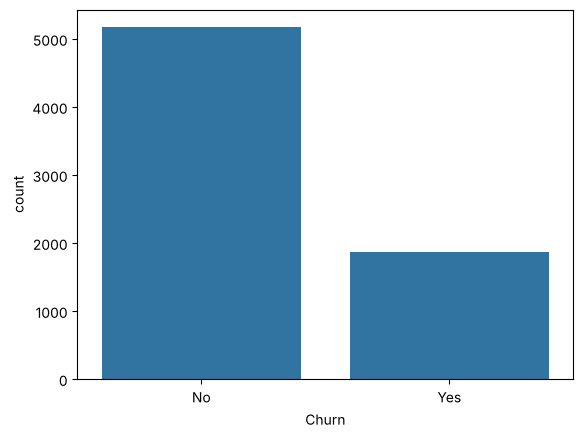

In [13]:
sns.countplot(data=df, x="Churn")
plt.show()

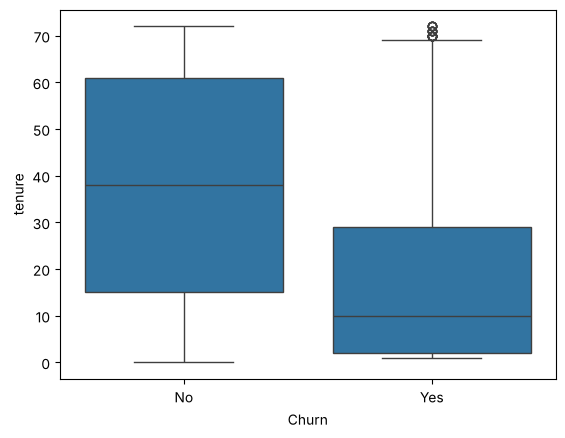

In [14]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.show()

Customers who churn tend to have shorter tenures, while customers who stay generally have longer tenures. The churn distribution also contains some high-tenure outliers. Customers who stay have a wider IQR, indicating more variability in tenure

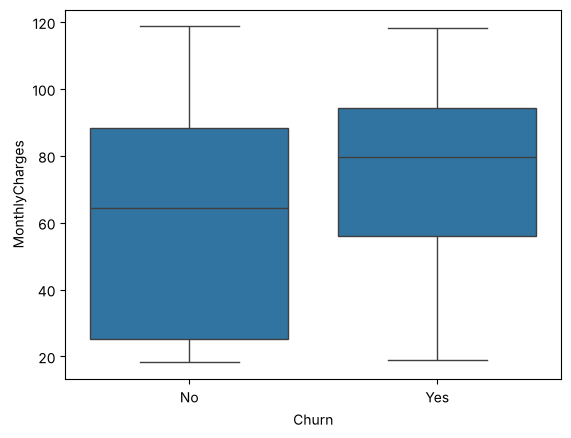

In [15]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.show()

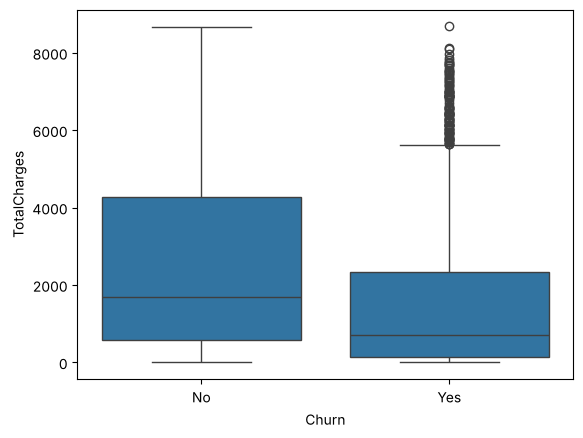

In [16]:
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.show()

Using the overall IQR rule, we found no numerical values outside the usual bounds. However, boxplots calculate their whiskers separately for each Churn group, so a value can appear as an outlier within one group even when it is not an outlier in the full dataset. These values are not automatically errors, so we will keep them.

Customers who churn have a lower median TotalCharges and a narrower central range than customers who stay. Customers who stay generally accumulate higher total charges, while the churn group contains fewer long-tenure customers. The churn group also has several high-value outliers.

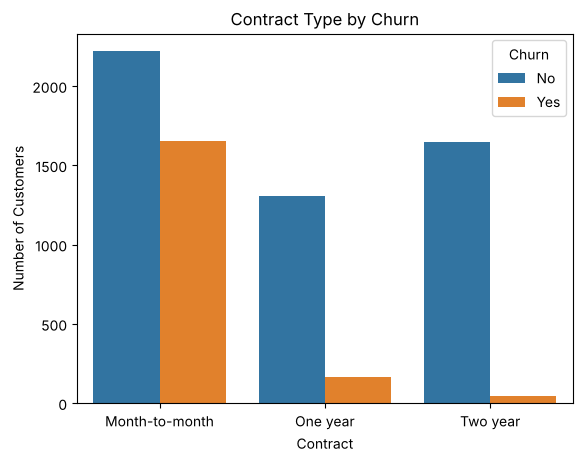

In [17]:
sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Contract Type by Churn')
plt.xlabel('Contract')
plt.ylabel('Number of Customers')
plt.show()

In [18]:
#churn rate 
churn_rate_monthly = df[df['Contract'] == 'Month-to-month']['Churn'].value_counts(normalize=True)['Yes']
churn_rate_1year = df[df['Contract'] == 'One year']['Churn'].value_counts(normalize=True)['Yes']
churn_rate_2year = df[df['Contract'] == 'Two year']['Churn'].value_counts(normalize=True)['Yes']

print('Churn rate for Month-to-Month contract:', churn_rate_monthly)
print('Churn rate for One-Year contract:', churn_rate_1year)
print('Churn rate for Two-Year contract:', churn_rate_2year)

Churn rate for Month-to-Month contract: 0.4270967741935484
Churn rate for One-Year contract: 0.11269517990495587
Churn rate for Two-Year contract: 0.02831858407079646


We observe that customers with month-to-month contracts have the highest churn rate (42.7%), compared to customers with one-year (11.3%) and two-year (2.8%) contracts. This suggests that month-to-month customers are more likely to churn than customers with longer-term contracts.

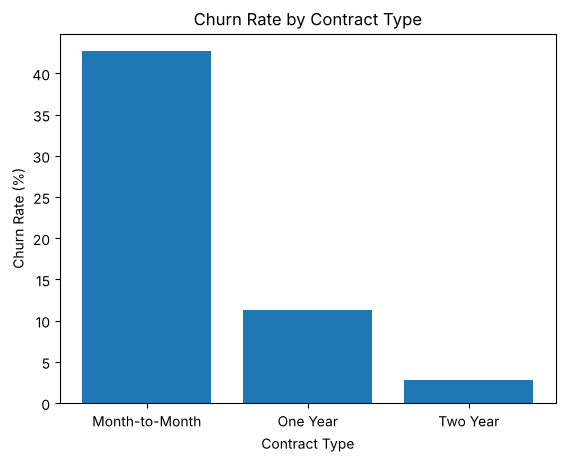

In [19]:
y_churn_rate = [churn_rate_monthly*100, churn_rate_1year*100, churn_rate_2year*100] 
x_contract_types = ['Month-to-Month', 'One Year', 'Two Year']
plt.bar(x_contract_types, y_churn_rate)
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.show()

In [20]:
# internet = df['InternetService'].unique()
# print(internet)
DSL_churn_rate = df[df['InternetService'] == 'DSL']['Churn'].value_counts(normalize=True)['Yes']
Fiber_churn_rate = df[df['InternetService'] == 'Fiber optic']['Churn'].value_counts(normalize=True)['Yes']
no_internet_churn_rate = df[df['InternetService'] == 'No']['Churn'].value_counts(normalize=True)['Yes']
 
print('Churn rate for DSL internet service:', DSL_churn_rate)
print('Churn rate for Fiber optic internet service:', Fiber_churn_rate)
print('Churn rate for No internet service:', no_internet_churn_rate)


Churn rate for DSL internet service: 0.1895910780669145
Churn rate for Fiber optic internet service: 0.4189276485788114
Churn rate for No internet service: 0.07404980340760157


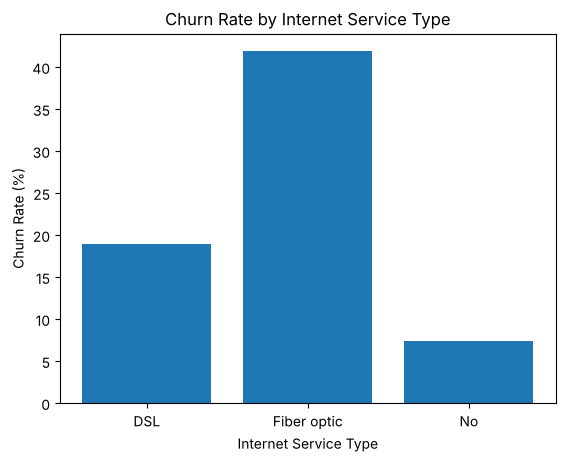

In [21]:
plt.bar(['DSL', 'Fiber optic', 'No'], [DSL_churn_rate*100, Fiber_churn_rate*100, no_internet_churn_rate*100])
plt.title('Churn Rate by Internet Service Type')
plt.xlabel('Internet Service Type')
plt.ylabel('Churn Rate (%)')
plt.show()

We observe that customers with fiber optic internet have the highest churn rate (41.9%), while customers without internet service have the lowest (7.4%).

In [22]:
table = pd.crosstab(df[df['Churn'] == 'Yes']['Contract'], df[df['Churn'] == 'Yes']['InternetService'], margins=True, normalize='index')
print(table)

InternetService       DSL  Fiber optic        No
Contract                                        
Month-to-month   0.238066     0.702115  0.059819
One year         0.319277     0.626506  0.054217
Two year         0.250000     0.645833  0.104167
All              0.245586     0.693954  0.060460


We observe that the majority of churned customers use fiber optic internet service (69.4%, versus 44.0% of all customers). This suggests a potential association between fiber optic service and customer churn, which could be investigated further.

In [23]:
# print(df['PaymentMethod'].unique())
Electronic_check_churn_rate = df[df['PaymentMethod'] == 'Electronic check']['Churn'].value_counts(normalize=True)['Yes']
Mailed_check_churn_rate = df[df['PaymentMethod'] == 'Mailed check']['Churn'].value_counts(normalize=True)['Yes']
Bank_transfer_churn_rate = df[df['PaymentMethod'] == 'Bank transfer (automatic)']['Churn'].value_counts(normalize=True)['Yes']
Credit_card_churn_rate = df[df['PaymentMethod'] == 'Credit card (automatic)']['Churn'].value_counts(normalize=True)['Yes']

print('Churn rate for Electronic check payment method:', Electronic_check_churn_rate)
print('Churn rate for Mailed check payment method:', Mailed_check_churn_rate)
print('Churn rate for Bank transfer payment method:', Bank_transfer_churn_rate)
print('Churn rate for Credit card payment method:', Credit_card_churn_rate)

Churn rate for Electronic check payment method: 0.4528541226215645
Churn rate for Mailed check payment method: 0.19106699751861042
Churn rate for Bank transfer payment method: 0.16709844559585493
Churn rate for Credit card payment method: 0.15243101182654403


We observe that customers who use electronic checks have the highest churn rate (45.3%), while customers who use credit cards have the lowest (15.2%). This suggests a potential association between payment method and customer churn.

In [24]:
partner_churn_rate = df[df['Partner'] == 'Yes']['Churn'].value_counts(normalize=True)['Yes']
no_partner_churn_rate = df[df['Partner'] == 'No']['Churn'].value_counts(normalize=True)['Yes']

print('Churn rate for customers with a partner:', partner_churn_rate)
print('Churn rate for customers without a partner:', no_partner_churn_rate)

Churn rate for customers with a partner: 0.1966490299823633
Churn rate for customers without a partner: 0.32957978577313923


We observe that customers without a partner have a higher churn rate (33.0%) than customers with a partner (19.7%). This suggests a potential association between partner status and customer churn.

In [25]:
Dependent_churn_rate = df[df['Dependents'] == 'Yes']['Churn'].value_counts(normalize=True)['Yes']
Independent_churn_rate = df[df['Dependents'] == 'No']['Churn'].value_counts(normalize=True)['Yes']

print('Churn rate for customers with dependents:', Dependent_churn_rate)
print('Churn rate for customers without dependents:', Independent_churn_rate)

Churn rate for customers with dependents: 0.15450236966824646
Churn rate for customers without dependents: 0.3127914048246503


We observe that customers without dependents have a higher churn rate (31.3%) than customers with dependents (15.5%). This suggests a potential association between having dependents and customer churn.

Now we will calculate the number of customers in each category : 


In [26]:
dependent_counts = df['Dependents'].value_counts()
print(dependent_counts)

Dependents
No     4933
Yes    2110
Name: count, dtype: int64


In [27]:
senior_citizen_churn_rate = df[df['SeniorCitizen'] == 1]['Churn'].value_counts(normalize=True)['Yes']
non_senior_citizen_churn_rate = df[df['SeniorCitizen'] == 0]['Churn'].value_counts(normalize=True)['Yes']

print('Churn rate for senior citizens:', senior_citizen_churn_rate)
print('Churn rate for non-senior citizens:', non_senior_citizen_churn_rate)


Churn rate for senior citizens: 0.4168126094570928
Churn rate for non-senior citizens: 0.23606168446026096


We observe that senior citizens have a higher churn rate (41.7%) than non-senior citizens (23.6%). This suggests an association between senior citizen status and customer churn.

In [28]:
cat_cols = df.select_dtypes(exclude='number').columns

for column in cat_cols:
    print(column, '→', df[column].unique().tolist())

gender → ['Female', 'Male']
Partner → ['Yes', 'No']
Dependents → ['No', 'Yes']
PhoneService → ['No', 'Yes']
MultipleLines → ['No phone service', 'No', 'Yes']
InternetService → ['DSL', 'Fiber optic', 'No']
OnlineSecurity → ['No', 'Yes', 'No internet service']
OnlineBackup → ['Yes', 'No', 'No internet service']
DeviceProtection → ['No', 'Yes', 'No internet service']
TechSupport → ['No', 'Yes', 'No internet service']
StreamingTV → ['No', 'Yes', 'No internet service']
StreamingMovies → ['No', 'Yes', 'No internet service']
Contract → ['Month-to-month', 'One year', 'Two year']
PaperlessBilling → ['Yes', 'No']
PaymentMethod → ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn → ['No', 'Yes']


## 05. Train/Test Split

The exploratory analysis above used the full dataset for description only; no feature, encoding, model or threshold choice was derived from it. From here on the test set is held out: it is not used to fit, tune or choose anything.

In [29]:
y = df['Churn'].map({'Yes': 1, 'No': 0})

X = df.drop('Churn', axis=1)

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=19 , stratify=y)

In [30]:
print(X_train.shape , X_test.shape , y_train.shape , y_test.shape)

one_train = y_train.value_counts(normalize=True)[1]
one_test = y_test.value_counts(normalize=True)[1]

print("Proportion of churned customers in training set:", one_train*100 , '%')
print("Proportion of churned customers in test set:", one_test*100 , '%')

(5634, 19) (1409, 19) (5634,) (1409,)
Proportion of churned customers in training set: 26.53532126375577 %
Proportion of churned customers in test set: 26.54364797728886 %


## 06. Preprocessing Plan

In [31]:
print(X_train.select_dtypes(include=['number']).columns)
print(X_train.select_dtypes(exclude=['number']).columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


tenure, MonthlyCharges, and TotalCharges are continuous numerical features.

SeniorCitizen and the text-based columns are categorical features. We will one-hot encode them, while numerical features will be scaled.

All preprocessing must be fitted on the training set only, so the test set remains unseen and does not cause data leakage.

## 07. Preprocessing Pipeline

In [32]:
column_transformer = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), ['tenure' , 'MonthlyCharges' , 'TotalCharges']),
        ('encoder', OneHotEncoder(handle_unknown='ignore'), ['SeniorCitizen', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'])
    ]
)

## 08. Baseline Model — Logistic Regression

In [33]:
pipeline = Pipeline(steps=[
    ('preprocessor', column_transformer),
    ('classifier', LogisticRegression(max_iter=1000, random_state=19))
])

In [34]:
pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [35]:
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]  # Get probabilities for the positive class (churn)

This is the only time the untuned baseline is scored on the test set, as a reference point. All model selection below uses cross-validation on the training set only.

In [36]:
confusion_mtx = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("Confusion Matrix:\n", confusion_mtx)
print("\nClassification Report:\n", report)
print("\nROC-AUC Score:\n", roc_auc)



Confusion Matrix:


 [[934 101]
 [167 207]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.67      0.55      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


ROC-AUC Score:
 0.8563899868247694


## 09. Baseline Evaluation

The logistic regression model achieved an accuracy of 81%, which is higher than the 73.5% majority-class baseline. It also achieved a ROC-AUC of 0.856, indicating that the model has a good ability to distinguish between customers who churn and those who do not.

However, the model correctly identified only 207 of the 374 actual churners, missing 167 churners. Therefore, recall is an important metric for this problem, especially if the goal is to identify customers at risk of churning.

## 10. Cross-Validated Baselines — Decision Tree vs Logistic Regression

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=19)
print(cv)

StratifiedKFold(n_splits=5, random_state=19, shuffle=True)


In [38]:
pipeline_dt = Pipeline(steps=[
    ('preprocessor' , column_transformer), 
    ('classifier', DecisionTreeClassifier(random_state=19))
])

In [39]:
tree_scores = cross_validate(pipeline_dt, X_train, y_train, cv=cv, scoring=['roc_auc' , 'accuracy' , 'precision' , 'recall' , 'f1'])
print("Cross-Validation Scores:")
for metric, scores_list in tree_scores.items():
    print(f"{metric}: {scores_list}")

Cross-Validation Scores:
fit_time: [0.0466218  0.04504943 0.04402375 0.04534888 0.04407597]
score_time: [0.02611184 0.02554464 0.02574134 0.0256567  0.02604747]
test_roc_auc: [0.6450992  0.64632107 0.6579904  0.64995638 0.6379447 ]
test_accuracy: [0.71960958 0.71428571 0.72670807 0.71960958 0.71847247]
test_precision: [0.47249191 0.46417445 0.48553055 0.47301587 0.46979866]
test_recall: [0.48829431 0.49832776 0.50501672 0.49832776 0.46822742]
test_f1: [0.48026316 0.48064516 0.49508197 0.48534202 0.46901173]


In [40]:
for metric in ['roc_auc', 'accuracy', 'precision', 'recall', 'f1']:
    values = tree_scores[f'test_{metric}']
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

roc_auc: 0.647 ± 0.007
accuracy: 0.720 ± 0.004
precision: 0.473 ± 0.007
recall: 0.492 ± 0.013
f1: 0.482 ± 0.008


In [41]:
logistic_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=['roc_auc' , 'accuracy' , 'precision' , 'recall' , 'f1'])
print("\nLogistic Regression Cross-Validation Scores:")
for metric, scores_list in logistic_scores.items():
    print(f"{metric}: {scores_list}")


Logistic Regression Cross-Validation Scores:
fit_time: [0.02987361 0.03821898 0.03369021 0.03532672 0.03083491]
score_time: [0.02983403 0.02505684 0.02472234 0.02519798 0.02534556]
test_roc_auc: [0.85219249 0.83987285 0.82645049 0.8450471  0.84570495]
test_accuracy: [0.79946761 0.81632653 0.78793256 0.81011535 0.79751332]
test_precision: [0.63369963 0.68253968 0.62096774 0.67489712 0.65236052]
test_recall: [0.57859532 0.57525084 0.51505017 0.54849498 0.5083612 ]
test_f1: [0.6048951  0.62431942 0.5630713  0.60516605 0.57142857]


In [42]:
for metric in ['roc_auc', 'accuracy', 'precision', 'recall', 'f1']:
    values = logistic_scores[f'test_{metric}']
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

roc_auc: 0.842 ± 0.009
accuracy: 0.802 ± 0.010
precision: 0.653 ± 0.023
recall: 0.545 ± 0.029
f1: 0.594 ± 0.023


Logistic Regression performed better than the untuned Decision Tree across ROC-AUC, accuracy, precision, recall, and F1-score. Therefore, Logistic Regression is currently the stronger baseline.

## 11. Hyperparameter Tuning — Decision Tree and Logistic Regression

In [43]:
param_grid = {
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_leaf': [1, 2, 5, 10 , 20]
}
grid_search = GridSearchCV(pipeline_dt, param_grid=param_grid , cv=cv , scoring='roc_auc' , n_jobs=-1)

grid_search.fit(X_train, y_train)

print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation score: ", grid_search.best_score_)
print("Best estimator: ", grid_search.best_estimator_)

Best parameters found:  {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10}
Best cross-validation score:  0.8268344883769941
Best estimator:  Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['SeniorCitizen', 'gender',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
       

In [44]:
best_tree_scores = cross_validate(grid_search.best_estimator_, X_train, y_train, cv=cv, scoring=['roc_auc' , 'accuracy' , 'precision' , 'recall' , 'f1'])

print("\nBest Decision Tree Cross-Validation Scores:")
for metric, scores_list in best_tree_scores.items():
    print(f"{metric}: {scores_list}")


Best Decision Tree Cross-Validation Scores:
fit_time: [0.0328126  0.03287792 0.03197503 0.03148174 0.03170824]
score_time: [0.02576566 0.02503157 0.02549553 0.02427626 0.02518129]
test_roc_auc: [0.82994846 0.8338241  0.81088128 0.83062301 0.82889559]
test_accuracy: [0.79680568 0.80035492 0.77994676 0.79946761 0.78241563]
test_precision: [0.61513158 0.64230769 0.58823529 0.62207358 0.62735849]
test_recall: [0.62541806 0.55852843 0.56856187 0.62207358 0.44481605]
test_f1: [0.62023217 0.59749553 0.57823129 0.62207358 0.52054795]


In [45]:
for metric in ['roc_auc', 'accuracy', 'precision', 'recall', 'f1']:
    values = best_tree_scores[f'test_{metric}']
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

roc_auc: 0.827 ± 0.008
accuracy: 0.792 ± 0.009
precision: 0.619 ± 0.018
recall: 0.564 ± 0.065
f1: 0.588 ± 0.037


In [46]:
param_grid_logistic = {
    'classifier__C' : [0.01 , 0.1 , 1 , 10  , 100 ]
}

grid_search_logistic = GridSearchCV(pipeline , param_grid=param_grid_logistic, cv=cv, scoring='roc_auc', n_jobs=-1)

grid_search_logistic.fit(X_train,  y_train)


print("Best parameters found: ", grid_search_logistic.best_params_)
print("Best cross-validation score: ", grid_search_logistic.best_score_)


Best parameters found:  {'classifier__C': 100}
Best cross-validation score:  0.8419457148723201


In [47]:
pd.DataFrame(grid_search_logistic.cv_results_)[['param_classifier__C', 'mean_test_score']]

,param_classifier__C,mean_test_score
0,0.01,0.839345
1,0.10,0.841249
2,1.00,0.841854
3,10.00,0.841875
4,100.00,0.841946


`C = 100` is the largest value in the grid, so we check the neighbours: the CV ROC-AUC is almost flat for `C >= 1`, so the edge of the grid does not matter here.

## 12. Random Forest — Baseline and Tuning

In [48]:
pipeline_rf = Pipeline(steps=[
    ('preprocessor' , column_transformer) , 
    ('classifier' , RandomForestClassifier(random_state=19 , n_jobs=-1))
]
)

In [49]:
rf_scores = cross_validate(pipeline_rf , X_train , y_train , cv=cv , scoring=['roc_auc' , 'accuracy' , 'precision' , 'recall' , 'f1'] )

for metric in ['roc_auc', 'accuracy', 'precision', 'recall', 'f1']:
    values = rf_scores[f'test_{metric}']
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")


roc_auc: 0.816 ± 0.008
accuracy: 0.785 ± 0.004
precision: 0.624 ± 0.011
recall: 0.476 ± 0.007
f1: 0.540 ± 0.008


In [50]:
param_grid_rf = {
    'classifier__n_estimators' : [200 , 400] ,
    'classifier__max_depth' : [None , 5 , 10 , 20] , 
    'classifier__min_samples_leaf' : [1 , 2 , 5], 
    'classifier__max_features' : ['sqrt' , 'log2']
}

grid_search_rf = GridSearchCV(pipeline_rf ,param_grid=param_grid_rf , cv=cv , scoring='roc_auc' , n_jobs=-1)

grid_search_rf.fit(X_train, y_train)

print("Best parameters found: ", grid_search_rf.best_params_)
print("Best cross-validation score: ", grid_search_rf.best_score_)


Best parameters found:  {'classifier__max_depth': 10, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 400}
Best cross-validation score:  0.841284041786747


## 13. Gradient Boosting — Baseline and Tuning

In [51]:
pipeline_gr_boost = Pipeline(steps=[
    ('preprocessor' , column_transformer) ,
    ('classifier' , GradientBoostingClassifier(random_state=19))
])

In [52]:
result_gd_boost = cross_validate(pipeline_gr_boost , X_train , y_train , cv=cv , scoring=['accuracy' , 'f1' , 'roc_auc' , 'precision' , 'recall'])

for metric in ['accuracy' , 'f1' , 'roc_auc' , 'precision' , 'recall']:
    value = result_gd_boost[f'test_{metric}']
    print(f'{metric} : {value.mean():.3f} ± {value.std():.3f} ')

accuracy : 0.799 ± 0.008 
f1 : 0.576 ± 0.019 
roc_auc : 0.842 ± 0.009 
precision : 0.656 ± 0.021 
recall : 0.514 ± 0.022 


In [53]:
param_grid_gb_refined = {
    'classifier__n_estimators': [200, 300, 400],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [1],
    'classifier__min_samples_leaf': [3, 5, 10]
}

grid_search_gb_refined = GridSearchCV(
    pipeline_gr_boost,
    param_grid=param_grid_gb_refined,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search_gb_refined.fit(X_train, y_train)

print("Best parameters:", grid_search_gb_refined.best_params_)
print("Best CV ROC-AUC:", grid_search_gb_refined.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 1, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 400}
Best CV ROC-AUC: 0.8465796351041606


The best `learning_rate` and `n_estimators` sit at the upper edge of this grid, and the depth was fixed to 1 (decision stumps). We check a wider grid before moving on.

In [54]:
param_grid_gb_wide = {
    'classifier__n_estimators': [400, 800],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [1, 2, 3],
    'classifier__min_samples_leaf': [5]
}
grid_search_gb_wide = GridSearchCV(pipeline_gr_boost, param_grid=param_grid_gb_wide, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_search_gb_wide.fit(X_train, y_train)

wide = pd.DataFrame(grid_search_gb_wide.cv_results_)[['param_classifier__n_estimators', 'param_classifier__learning_rate', 'param_classifier__max_depth', 'mean_test_score']]
print(wide.sort_values('mean_test_score', ascending=False).round(4).to_string(index=False))

 param_classifier__n_estimators  param_classifier__learning_rate  param_classifier__max_depth  mean_test_score
                            400                             0.10                            1           0.8466
                            800                             0.05                            1           0.8465
                            800                             0.10                            1           0.8465
                            400                             0.05                            1           0.8458
                            400                             0.05                            2           0.8425
                            800                             0.05                            2           0.8394
                            400                             0.05                            3           0.8394
                            400                             0.10                            2           0.8391
 

The wider search does not help: more trees give no gain, and deeper trees are clearly worse (they overfit). Depth-1 boosting with 400 trees stays the best, so we keep `grid_search_gb_refined` as the Gradient Boosting model.

## 14. Model Comparison and Selection

All four tuned models are compared with the same 5 stratified folds on the training set (ROC-AUC).

In [55]:
def fold_scores(gs):
    i = gs.best_index_
    return np.array([gs.cv_results_[f'split{k}_test_score'][i] for k in range(cv.get_n_splits())])

models_cv = {
    'Decision Tree (tuned)': grid_search,
    'Logistic Regression (tuned)': grid_search_logistic,
    'Random Forest (tuned)': grid_search_rf,
    'Gradient Boosting (tuned)': grid_search_gb_refined,
}
comparison = pd.DataFrame({
    name: {'cv_roc_auc_mean': gs.best_score_, 'cv_roc_auc_std': fold_scores(gs).std(ddof=1)}
    for name, gs in models_cv.items()
}).T.sort_values('cv_roc_auc_mean', ascending=False)
print(comparison.round(4))

# same folds for every model -> fold-by-fold (paired) differences are meaningful
diff_gb_lr = fold_scores(grid_search_gb_refined) - fold_scores(grid_search_logistic)
print('\nGB minus LR, per fold:', diff_gb_lr.round(4))
print(f'mean = {diff_gb_lr.mean():.4f}, std = {diff_gb_lr.std(ddof=1):.4f}')

                             cv_roc_auc_mean  cv_roc_auc_std
Gradient Boosting (tuned)             0.8466          0.0084
Logistic Regression (tuned)           0.8419          0.0098
Random Forest (tuned)                 0.8413          0.0084
Decision Tree (tuned)                 0.8268          0.0091

GB minus LR, per fold: [0.0012 0.0076 0.0063 0.0077 0.0005]
mean = 0.0046, std = 0.0035


Gradient Boosting has the highest CV ROC-AUC, but only by a small margin over the tuned Logistic Regression and Random Forest, and it beats Logistic Regression in every fold. We keep Gradient Boosting as the final model. Logistic Regression is almost as good, far simpler and easier to explain, so it would also be a defensible choice.

The CV score of the winning model is slightly optimistic, because it was picked as the best of many candidates on the same folds.

## 15. Out-of-Fold Predictions and Cost-Based Threshold Selection

In [56]:
oof_proba_gb = cross_val_predict(grid_search_gb_refined.best_estimator_ , X_train , y_train , cv=cv , method='predict_proba')[: , 1]
print(f'The shape : {oof_proba_gb.shape}')
print(f'The mean : {oof_proba_gb.mean()}')
print(f'The roc_auc score : {roc_auc_score(y_train, oof_proba_gb)}')

The shape : (5634,)
The mean : 0.2656712487192812
The roc_auc score : 0.8469177680938555


In [57]:
thresholds = np.arange(0.02 , 0.70 + 0.01 , 0.01 )
COST_FN = 600 
COST_FP = 50
rows = []
for threshold in thresholds:
    oof_gb = (oof_proba_gb >= threshold).astype(int)
    TP = np.sum((oof_gb == 1) & (y_train == 1))
    TN = np.sum((oof_gb == 0) & (y_train == 0))
    FP = np.sum((oof_gb == 1) & (y_train == 0))
    FN = np.sum((oof_gb == 0) & (y_train == 1))


    recall_bg = TP / (TP + FN) if (TP + FN) > 0 else 0
    precision_bg = TP / (TP + FP) if (TP + FP) > 0 else 0
    flagged_number = np.sum(oof_gb)



    rows.append({"threshold" : round(threshold , 2) , 
                 "recall" : recall_bg , 
                 "precision" : precision_bg , 
                 "flagged" : flagged_number , 
                 "TP" : TP , "FP" : FP , "TN" : TN , "FN" : FN ,
                 "total_cost" : COST_FN*FN + COST_FP*FP})

threshold_table = pd.DataFrame(rows)



In [58]:
min_cost_idx = threshold_table['total_cost'].idxmin()

print(f'the threshold with minimal cost : \n{threshold_table.iloc[min_cost_idx]}')

print(threshold_table[threshold_table['threshold'] == 0.5])


the threshold with minimal cost : 
threshold          0.070000
recall             0.965886
precision          0.373513
flagged         3866.000000
TP              1444.000000
FP              2422.000000
TN              1717.000000
FN                51.000000
total_cost    151700.000000
Name: 5, dtype: float64
    threshold    recall  precision  flagged   TP   FP    TN   FN  total_cost
48        0.5  0.525753   0.663851     1184  786  398  3741  709      445300


In [59]:
contact_nobody = y_train.sum() * COST_FN
contact_everyone = (len(y_train) - y_train.sum()) * COST_FP

print(f'Cost of contacting nobody: {contact_nobody}')
print(f'Cost of contacting everyone: {contact_everyone}')

Cost of contacting nobody: 897000
Cost of contacting everyone: 206950


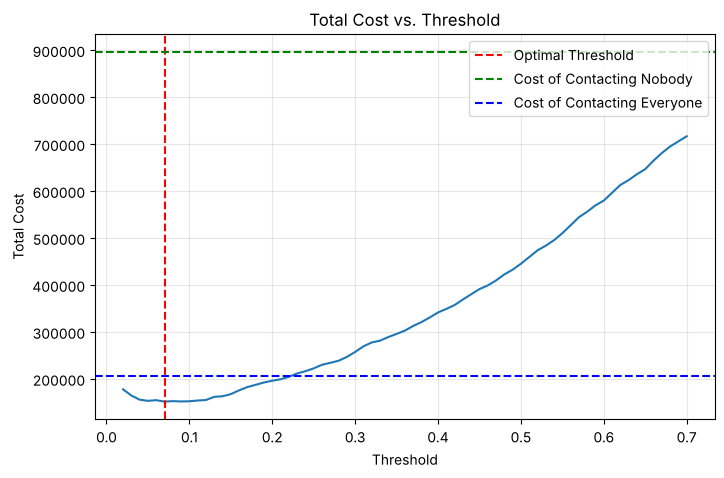

In [60]:
plt.figure(figsize=(8 , 5))
plt.plot(threshold_table['threshold'], threshold_table['total_cost'])
plt.axvline(x=threshold_table.iloc[min_cost_idx]['threshold'], color='r', linestyle='--', label='Optimal Threshold')
plt.axhline(y=contact_nobody, color='g', linestyle='--', label='Cost of Contacting Nobody')
plt.axhline(y=contact_everyone, color='b', linestyle='--', label='Cost of Contacting Everyone')
plt.title('Total Cost vs. Threshold')
plt.xlabel('Threshold')
plt.ylabel('Total Cost')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Choosing a threshold from business cost

**Assumptions** (illustrative values chosen for this project, not real business data)
- A missed churner (FN) costs **600** (lost revenue).
- A retention offer sent to a customer who would have stayed (FP) costs **50**.
- Total cost = `600 × FN + 50 × FP`.
- Simplifications: every contacted churner is assumed to be saved, and the 50 offer cost for correctly contacted churners (TP) is ignored.

**Result** (out-of-fold predictions on the training set)

| Strategy | Total cost |
|---|---:|
| Contact nobody | 897,000 |
| Default threshold 0.50 | 445,300 |
| Contact everyone | 206,950 |
| Cheapest threshold (0.07) | 151,700 |

**Takeaway**
The model beats both baselines, but its saving over "contact everyone" is only about 27%, because a missed churner costs 12× more than a wasted offer. The cost curve is also very flat between about 0.05 and 0.10, so the exact threshold within that range matters little.

In [61]:
FINAL_THRESHOLD = 0.10
threshold_table[threshold_table['threshold'].round(2) == FINAL_THRESHOLD]

,threshold,recall,precision,flagged,TP,FP,TN,FN,total_cost
8,0.1,0.947826,0.401416,3530,1417,2113,2026,78,152450


### Final threshold: 0.10

Under the assumed costs, 0.07 gives the lowest out-of-fold cost (151,700), but 0.10 costs only 750 more (152,450, about 0.5%) while contacting fewer customers (62.7% vs 68.6%). The cost model assumes every contacted churner is saved, which is optimistic, so a slightly higher threshold hedges against lower offer success (checked in the sensitivity analysis below).

The model, its hyperparameters and the threshold were all chosen with training data only (cross-validation and out-of-fold predictions). The final model is scored on the test set once, in section 16.

### Sensitivity to the offer success rate

The simplified cost model above assumes that every contacted churner is saved and ignores the 50 offer cost for contacted churners. Here we use a fuller model: every contacted customer costs 50, and a contacted churner is saved only with probability `s` (otherwise the 600 is still lost):

`cost = 600 × FN + 50 × (TP + FP) + 600 × (1 − s) × TP`

This is a robustness check only; the threshold is **not** re-chosen from it.

In [62]:
def total_cost(y_true, flagged, save_rate):
    y_true = np.asarray(y_true)
    flagged = np.asarray(flagged).astype(bool)
    tp = (flagged & (y_true == 1)).sum()
    fp = (flagged & (y_true == 0)).sum()
    fn = (~flagged & (y_true == 1)).sum()
    return COST_FN * fn + COST_FP * (tp + fp) + COST_FN * (1 - save_rate) * tp

grid_thresholds = threshold_table['threshold'].to_numpy()
y_train_arr = y_train.to_numpy()
rows = []
for s in [1.0, 0.8, 0.6, 0.4, 0.2]:
    costs = np.array([total_cost(y_train_arr, oof_proba_gb >= t, s) for t in grid_thresholds])
    everyone = total_cost(y_train_arr, np.ones_like(y_train_arr), s)
    nobody = total_cost(y_train_arr, np.zeros_like(y_train_arr), s)
    best_naive = min(everyone, nobody)
    at_final = costs[np.isclose(grid_thresholds, FINAL_THRESHOLD)][0]
    rows.append({
        'save_rate': s,
        'best_threshold': grid_thresholds[costs.argmin()],
        'saving_at_best_%': 100 * (1 - costs.min() / best_naive),
        f'saving_at_{FINAL_THRESHOLD}_%': 100 * (1 - at_final / best_naive),
    })
print('Saving vs the better of "contact everyone" / "contact nobody" (out-of-fold, training set)')
print(pd.DataFrame(rows).round(2).to_string(index=False))

Saving vs the better of "contact everyone" / "contact nobody" (out-of-fold, training set)
 save_rate  best_threshold  saving_at_best_%  saving_at_0.1_%
       1.0            0.09             20.73            20.73
       0.8            0.12             14.82            14.70
       0.6            0.12             12.49            12.04
       0.4            0.22             11.86            10.55
       0.2            0.42              4.15            -0.72


The saving over the best naive strategy is smaller under this fuller model (about 21% at `s = 1`, versus 27% in the simplified model), and it shrinks as offers become less effective. A threshold of 0.10 stays close to the best threshold for `s` between 0.6 and 1, but if only about 20% of contacted churners can be saved, it is no better than contacting nobody and the best threshold moves much higher. The retention success rate is the number to measure in practice before trusting any of these cost figures.

## 16. Final Evaluation on the Test Set

The model (`grid_search_gb_refined.best_estimator_`, already refit on the whole training set) and the threshold (0.10) are frozen. This is the first and only time the final model is scored on the test set.

In [63]:
final_model = grid_search_gb_refined.best_estimator_
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= FINAL_THRESHOLD).astype(int)
y_test_arr = y_test.to_numpy()

print(f'Test ROC-AUC, final model : {roc_auc_score(y_test, test_proba):.4f}')
print(f'Test ROC-AUC, baseline LR : {roc_auc_score(y_test, y_proba):.4f}   (reference from section 08)')
print(f'\nConfusion matrix at threshold {FINAL_THRESHOLD}:\n', confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, target_names=['stays', 'churns']))
print(f'Share of customers flagged: {test_pred.mean():.1%}')

Test ROC-AUC, final model : 0.8616
Test ROC-AUC, baseline LR : 0.8564   (reference from section 08)

Confusion matrix at threshold 0.1:
 [[539 496]
 [ 20 354]]


              precision    recall  f1-score   support

       stays       0.96      0.52      0.68      1035
      churns       0.42      0.95      0.58       374

    accuracy                           0.63      1409
   macro avg       0.69      0.73      0.63      1409
weighted avg       0.82      0.63      0.65      1409

Share of customers flagged: 60.3%


In [64]:
def simple_cost(y_true, flagged):
    # same simplified cost as section 15: 600 per missed churner, 50 per wasted offer
    y_true = np.asarray(y_true)
    flagged = np.asarray(flagged).astype(bool)
    return COST_FN * (~flagged & (y_true == 1)).sum() + COST_FP * (flagged & (y_true == 0)).sum()

strategies = {
    f'Model, threshold {FINAL_THRESHOLD}': test_proba >= FINAL_THRESHOLD,
    'Model, threshold 0.50': test_proba >= 0.5,
    'Contact everyone': np.ones_like(y_test_arr),
    'Contact nobody': np.zeros_like(y_test_arr),
}
test_costs = pd.DataFrame({
    'simplified_cost': {k: simple_cost(y_test_arr, v) for k, v in strategies.items()},
    'full_cost_s=0.6': {k: total_cost(y_test_arr, v, 0.6) for k, v in strategies.items()},
})
print(test_costs.round(0).astype(int))

                       simplified_cost  full_cost_s=0.6
Model, threshold 0.1             36800           139460
Model, threshold 0.50           107650           166230
Contact everyone                 51750           160210
Contact nobody                  224400           224400


In [65]:
# Bootstrap the test set to see how uncertain these numbers are
rng = np.random.default_rng(19)
boot_auc, boot_saving = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    yb, pb = y_test_arr[idx], test_proba[idx]
    boot_auc.append(roc_auc_score(yb, pb))
    boot_saving.append(1 - simple_cost(yb, pb >= FINAL_THRESHOLD) / simple_cost(yb, np.ones_like(yb)))

print('95% bootstrap interval, ROC-AUC                          :', np.percentile(boot_auc, [2.5, 97.5]).round(3))
print('95% bootstrap interval, saving vs contact-everyone (simplified cost):', (100 * np.percentile(boot_saving, [2.5, 97.5])).round(1), '%')

95% bootstrap interval, ROC-AUC                          : [0.84  0.881]
95% bootstrap interval, saving vs contact-everyone (simplified cost): [18.5 38.2] %


## 17. What Drives the Predictions?

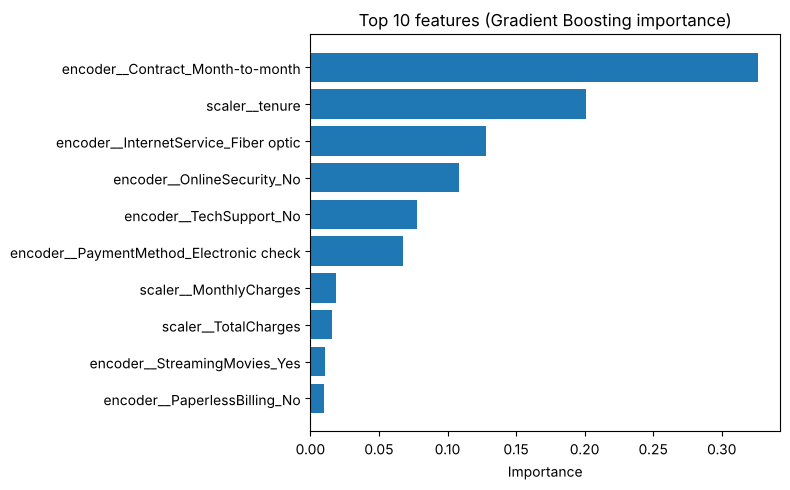

In [66]:
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()
importances = (pd.Series(final_model.named_steps['classifier'].feature_importances_, index=feature_names)
               .sort_values(ascending=False))
top = importances.head(10)

plt.figure(figsize=(8, 5))
plt.barh(top.index[::-1], top.values[::-1])
plt.title('Top 10 features (Gradient Boosting importance)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

Impurity-based importances only say which features the model used most; they do not show causes, and they can favour features with many distinct values.

## 18. Conclusions and Limitations

**Results**

- Final model: Gradient Boosting (400 depth-1 trees). CV ROC-AUC 0.847; test ROC-AUC 0.862 (95% bootstrap interval about 0.84 to 0.88), versus 0.856 for the baseline Logistic Regression on the same test set. The gain over the baseline is small.
- At the chosen threshold of 0.10 the model flags 60% of customers, catches 354 of the 374 churners (recall 0.95) and is right 42% of the time when it flags someone (precision).
- Under the illustrative costs, the test-set cost is 36,800, against 51,750 for contacting everyone (about 29% lower; 95% bootstrap interval roughly 18% to 38%) and 224,400 for contacting nobody. With the default 0.50 threshold the model costs 107,650, which is worse than contacting everyone. The business value here comes from choosing the threshold, not from accuracy.
- The features the model relies on most: month-to-month contract, short tenure, fiber optic internet, no online security, no tech support and electronic-check payment.

**Limitations**

- The costs (600 per missed churner, 50 per offer) are assumptions, not real figures. The sensitivity analysis shows the saving shrinks as offers become less effective, and at around a 20% success rate the model brings no benefit.
- The patterns above are associations, not causes. For example, fiber optic customers may churn because of price or competition rather than the technology itself.
- The test set is small (1,409 customers, 374 churners), so all test figures carry wide uncertainty.
- The differences between the tuned models are small (about 0.005 ROC-AUC between Gradient Boosting and Logistic Regression), and the data is a single snapshot with no time dimension. A real deployment would need validation on later months of data.
- This is a public sample dataset, so the results show the method rather than any real company's churn.

## 19. Save the Final Model

In [67]:
import joblib
from pathlib import Path

Path('../models').mkdir(exist_ok=True)
joblib.dump({'pipeline': final_model, 'threshold': FINAL_THRESHOLD}, '../models/churn_gb_pipeline.joblib')

['../models/churn_gb_pipeline.joblib']